In [81]:
using Dates
Dates.format(now(), "E, dd U yyyy HH:MM:SS")

"Thursday, 25 April 2024 12:33:01"

# Distribuciones continuas

Una función f(x) es una fdp para una va continua si 

1. $f(x)\ge 0$
2. $ \int_{-\infty}^\infty f(x)\,dx=1$


Si existe $F(x)$ Fda entonces se tiene:

$P(a < X < b)=F(b)-F(a)$

$P( X < a)=F(a)$

$P( X > a)=1-F(a)$

In [82]:
using Distributions, StatsPlots, Colors
gr()

Plots.GRBackend()

## Distribución uniforme

$$
f(x)=
\begin{cases}
\displaystyle\frac{1}{b-a} & a \le x < b \\
0 & \text{otro caso}
\end{cases}
$$
$$
F(x)=
\begin{cases}
0 & x < a \\
\int_{a}^{x}\frac{1}{b-a} dt=\displaystyle\frac{x-a}{b-a} & a \le x < b \\
1 & x \ge b
\end{cases}
$$

$$U(a,b)$$

parámetros a < b

In [83]:
d1=Uniform()

Uniform{Float64}(a=0.0, b=1.0)

## Colores en Julia

Para ver los colores con nombre propio vea [aqui](http://juliagraphics.github.io/Colors.jl/stable/namedcolors/)

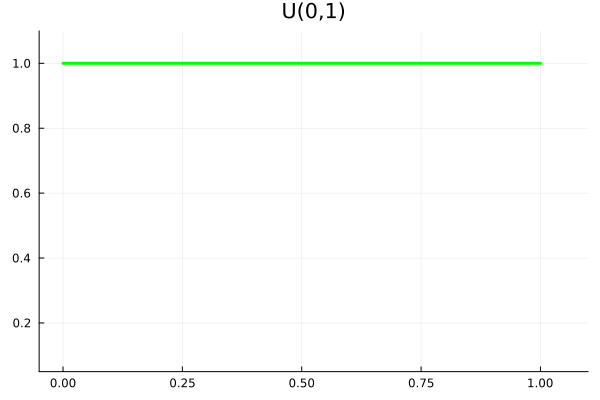

In [166]:
plot(d1, ylims=(0.05,1.1),xlims=(-0.05,1.1), legend=false,title="U(0,1)",lw=3, color=:lime)

$$
F(x)=
\begin{cases}
0 & x < 0 \\
\int_{0}^{x} dt=x & 0 \le x < 1 \\
1 & x \ge 1
\end{cases}
$$

In [85]:
function F(x)
    if x > 0 && x <1 
        return(x)
    elseif x < 0
        return(0)
    else x>1
        return(1)
    end
end 

F (generic function with 1 method)

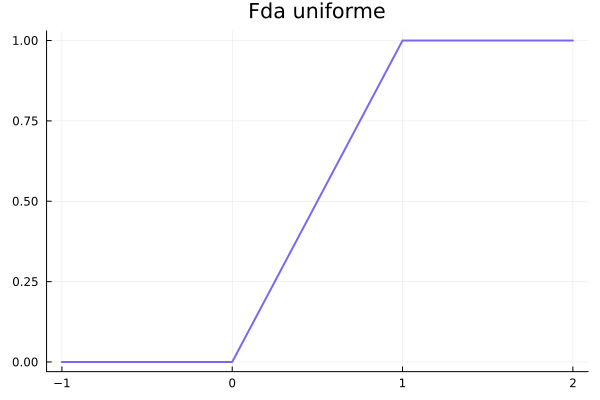

In [169]:
plot(F,-1,2,leg=false,color=:slateblue2,lw=2,title="Fda uniforme")

P(0.25 < X < 0.6)=

In [87]:
F(0.6)-F(0.25)

0.35

## Ejercicio

Suponga que el error que se comete al determinar la densidad de una sustancia es una VA uniforme entre -0.015 y 0.015, hallar la probabilidad de que:

1. el error esté entre 0.01 y 0.02

2. el error exceda 0.005.

In [88]:
a=-0.015
b=0.015
unif= Uniform(a,b)
cdf(unif, 0.02)-cdf(unif, 0.01) # 1.
ccdf(unif, 0.005)  # 2.

0.3333333333333333

## Distribución exponencial

$$
f(x)=
\begin{cases}
\displaystyle\frac{1}{\theta} e^{-\displaystyle\frac{x}{\theta}} & 0 \le x < \infty \\
0 & \text{otro caso}
\end{cases}
$$
$$
F(x)=
\begin{cases}
0 & x \le 0 \\
\int_{0}^{x}\frac{1}{\theta}e^{-\frac{t}{\theta}}dt=\displaystyle 1-e^{-\displaystyle\frac{x}{\theta}} &  x >0 
\end{cases}
$$
$$Exp(\theta)$$

In [89]:
d2=Exponential(3)

Exponential{Float64}(θ=3.0)

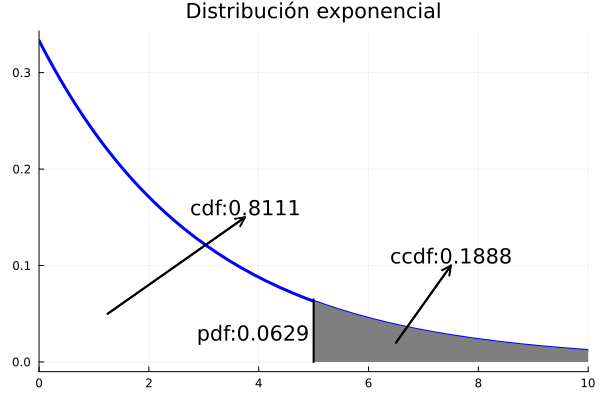

In [90]:
plot(d2, lw=3, xlims=[0,10], color=:blue,legend=false, title="Distribución exponencial")
plot!(d2,5,10, fillrange=0, color=:gray50)
plot!([5; 5], [0; 0.065], lw=2, lc=:black, legend=false)
plot!([6.5,7.5], [0.02,0.1], arrow=true, color=:black,linewidth=2)
plot!([1.25,3.75], [0.05,0.15], arrow=true, color=:black, lw=2)
annotate!(7.5,0.11, text("ccdf:0.1888"))
annotate!(3.75,0.16,text("cdf:0.8111"))
annotate!(3.9,0.03, text("pdf:0.0629"), :left)

In [91]:
cdf(d2,5)

0.8111243971624382

In [92]:
ccdf(d2,5)

0.18887560283756183

In [93]:
pdf(d2,5)

0.06295853427918728

In [94]:
cdf(d2,5)-cdf(d2,4)  # P(4 < X < 5)

0.07472153527816494

In [95]:
q1 = quantile(d2,0.4) # P(X < q)=0.4
q2 = cquantile(d2,0.3) # P(X > q)= 0.3
q1, q2, pdf(d2,q1), pdf(d2,q2)

(1.5324768712979722, 3.6119184129778086, 0.19999999999999998, 0.09999999999999999)

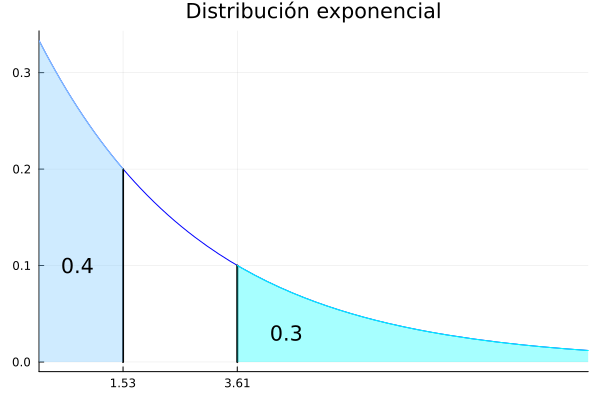

In [96]:
plot(d2, lw=1, xlims=[0,10], color=:blue,legend=false, title="Distribución exponencial")
plot!([1.53; 1.53], [0; .2], lw=2, lc=:black, legend=false)
plot!([3.61; 3.61], [0; 0.1], lw=2, lc=:black, legend=false)
plot!(d2, 3.61, 10, fillrange=0, color=:cyan1, fillalpha=0.35)
plot!(d2,0,1.53, fillrange=0,color=:skyblue1, fillalpha=0.4)
plot!(xtick=[1.53, 3.61])
annotate!(0.7,0.1, text("0.4"))
annotate!(4.5,.03,text("0.3"))


In [97]:
pdf(d2,5)

0.06295853427918728

$P(Exp(3) \leq 5)=$

In [98]:
cdf(d2,5)

0.8111243971624382

$P(Exp(3)>5)=$

In [99]:
ccdf(d2,5)

0.18887560283756183

In [100]:
F1(x)=1-1//3*exp(-x/3)

F1 (generic function with 1 method)

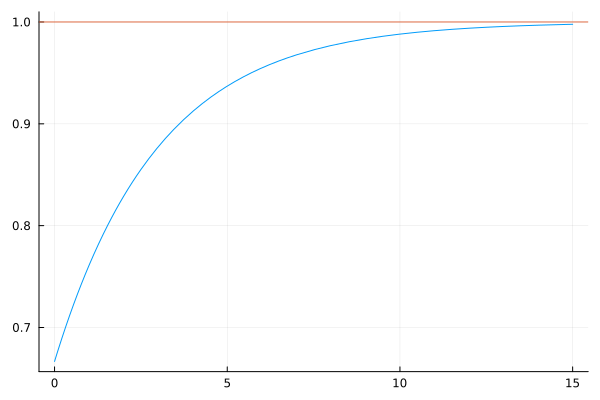

In [101]:
plot(F1,0,15,leg=false)
plot!([1],st=:hline)

In [102]:
mean(d2)

3.0

In [103]:
var(d2)

9.0

In [104]:
std(d2)

3.0

## Ejercicio

Suponga que el tiempo que pasan los clientes con el cajero tiene distribución exponencial con media de 3 minutos,¿Cual es la probabilidad de que:

1. un cliente dure más de 4 minutos?
2. dure entre 2 y 5 minutos?
3. ¿Cuál es el tiempo mínimo que demora el 7% de los clientes que más se demoran?

In [105]:
θ =3
Exp = Exponential(θ)
ccdf(Exp, 4) # 1.
cdf(Exp,5)-cdf(Exp,2) #2.
cquantile(Exp, 0.07) #3.

7.977780110798333

$F(x)=1-e^{-\frac{x}{3}}$

1. $1-F(4)$
2. $F(5)-F(2)$
3. $\int_{q}^{\infty}\frac{1}{3}e^{-\frac{x}{3}}\,dx=0.07$

## Distribución normal estándar
$$f(x)=\displaystyle\frac{1}{\sqrt{2\pi}}\,e^{\displaystyle-\frac{x^2}{2}}$$

$$N(\mu=0,\sigma=1)$$

In [106]:
d3=Normal()

Normal{Float64}(μ=0.0, σ=1.0)

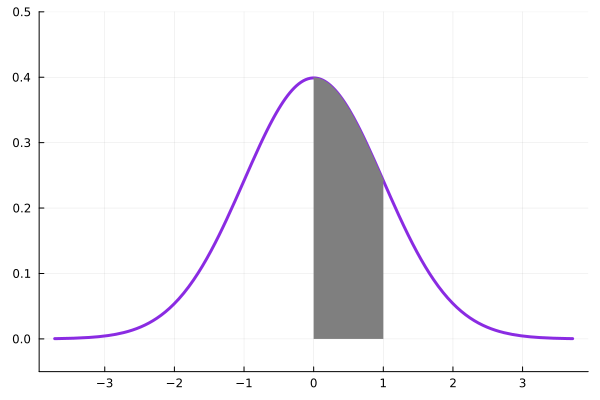

In [107]:
plot(d3, ylims=[-0.05,0.5], color=:blueviolet, legend=false, lw=3)
plot!(d3,0,1, fillrange=0, color=:gray50)


In [108]:
cdf(d3,1)-cdf(d3,0) 

0.34134474606854304

In [109]:
qn1 = quantile(d3, 0.05) # P(Z < qn1)=0.05

-1.6448536269514729

In [110]:
qn2 = cquantile(d3, 0.025) # P(Z > qn2)=0.025

1.9599639845400592

In [111]:
mean(d3)

0.0

In [112]:
var(d3)

1.0

## Distribución normal
$$\huge f(x)=\displaystyle\frac{1}{\sqrt{2\pi}\sigma}\,{e}^{-\displaystyle\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2}$$

$$\huge N(\mu, \sigma)$$

## Propiedades

1. $\displaystyle\lim_{x \to \pm \infty}f(x)=0$
   
2. Tiene un máximo en $(\mu, \displaystyle\frac{1}{\sqrt{2\pi\sigma^2}})$

3. Tiene puntos de inflexión en $x=\mu \pm \sigma$

In [113]:
d4=Normal(40,8)

Normal{Float64}(μ=40.0, σ=8.0)

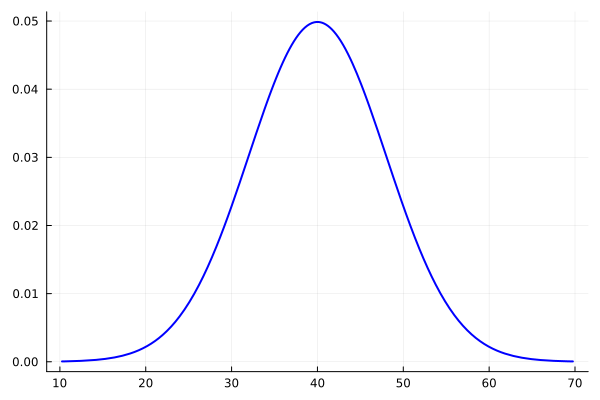

In [114]:
plot(d4, lw=2, color=:blue, legend=false)

In [115]:
mean(d4)

40.0

In [116]:
var(d4)

64.0

In [117]:
std(d4)

8.0

In [118]:
qn3 = quantile(d4,0.1)

29.747587475643197

In [119]:
qn4= cquantile(d4,0.15)

48.29146711595032

In [120]:
cdf(d4,30)-cdf(d4,20) # P( 20 < X < 30)

0.09944010834107912

## Ejercicio

Suponga que la estatura tiene distribución normal con media de 165 cms y desviación estándar de 8 cms. Si se escoge una persona al azar, ¿Cuál es la probabilidad de que:

1. mida más de 170 cms?
2. mida a lo más  160 cms?
3. mida entre 172 y 180 cms?
4. ¿Cuál es la estatura mínima del 8% de los más altos?
5. ¿Cuál es la estatura máxima del 5% de los más bajitos?

X: Estatura (cms)

In [121]:
μ = 165
σ = 8

8

In [122]:
nor = Normal(μ,σ)

Normal{Float64}(μ=165.0, σ=8.0)

In [123]:
ccdf(nor, 170) # P(X>170)

0.26598552904870054

In [124]:
cdf(nor, 160) # P(X < 160)

0.26598552904870054

In [125]:
cdf(nor, 180)-cdf(nor, 172)# P( 172 < X < 180)

0.16039059108724918

In [126]:
cquantile(nor, 0.08)

176.24057248247706

La estatura mínima del 8% de los más altos es de 176.24 cms 

In [127]:
quantile(nor, 0.05)

151.8411709843882

La estatura máxima del 5% de los más bajitos 151.84 cms

## Distribución chi-cuadrado

$$\chi^2_{(n)}=X_1^2+X_2^2+\dots+X_{n}^2$$
$$X_i \sim N(0,1)$$

   Por cada grado de libertad $n \in \mathbb{N}$ hay una distribución chi-cuadrado.

In [128]:
d5=Chisq(10)

Chisq{Float64}(ν=10.0)

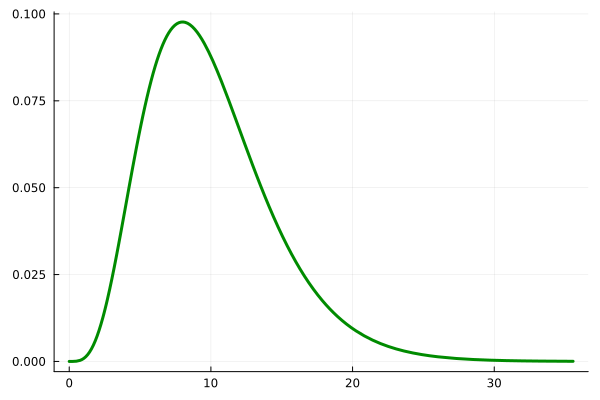

In [129]:
plot(d5, legend=false, color=:green4, lw=3)

In [130]:
mean(d5)

10.0

In [131]:
var(d5)

20.0

In [132]:
std(d5)

4.47213595499958

## Distribución t de Student

$$t_{(n)}=\displaystyle\frac{Z}{\sqrt{\displaystyle\frac{\chi^2_{(n)}}{n}}}$$
$$Z \sim N(0,1)$$

Por cada grado de libertad $n \in \mathbb{N}$ hay una distribución t.
Entre más grados de libertad más se acerca a la distribución normal estándar. Vea [t de Student](https://en.wikipedia.org/wiki/Student%27s_t-distribution). Una distribución t con infinitos grados de libertad es igual a una distribución normal estándar:

$$t_{(\infty)} \equiv N(0,1)$$

In [133]:
d6 = TDist(7)

TDist{Float64}(ν=7.0)

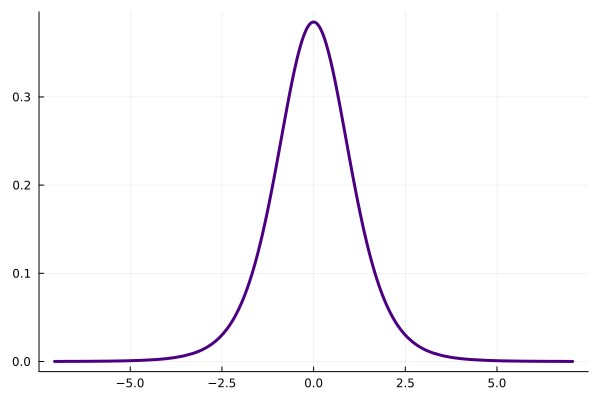

In [134]:
plot(d6,legend=false, color=:indigo, lw=3)

In [135]:
mean(d6)

0.0

In [136]:
var(d6)

1.4

In [137]:
std(d6)

1.1832159566199232

In [138]:
cdf(d6,-2)

0.04280966428148799

In [139]:
ccdf(d6,1)

0.17530833141010374

In [140]:
quantile(d6,0.9)

1.4149239276505088

## Distribución F de Fisher 

$$F(m,n)=\displaystyle\frac{\displaystyle\frac{\chi^2_{(m)}}{m}}{\displaystyle\frac{\chi^2_{(n)}}{n}}$$

[F-Fisher-Snedecor](https://en.wikipedia.org/wiki/F-distribution)

In [141]:
d7 = FDist(10,15)

FDist{Float64}(ν1=10.0, ν2=15.0)

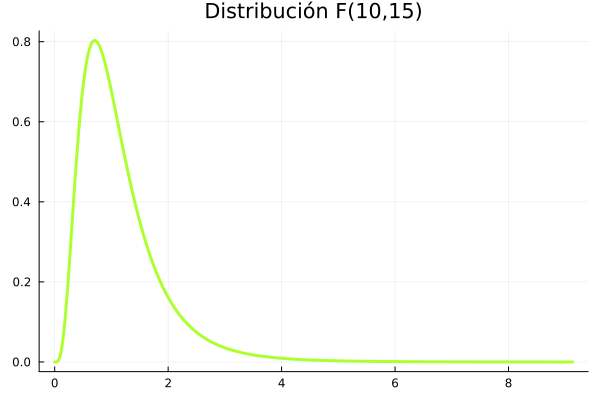

In [142]:
plot(d7,title="Distribución F(10,15)", legend=false, lw=3, color=:greenyellow)

In [143]:
mean(d7)

1.1538461538461537

In [144]:
var(d7)

0.556750941366326

In [145]:
std(d7)

0.7461574507879192

## Distribución triangular

In [146]:
function d8(x)
    if x > 0 && x <1 
        return(x)
    elseif x>1 && x<2
        return(2-x)
    else
        return(0)
    end
end 

d8 (generic function with 1 method)

In [1]:
function F8(x)
    if x < 0 
        return(0)
    elseif x>0 && x<1
        return(x^2/2)
    elseif x>1 && x <2
        return(-x^2/2+2*x-1)
    else    
        return(0)
    end
end

F8 (generic function with 1 method)

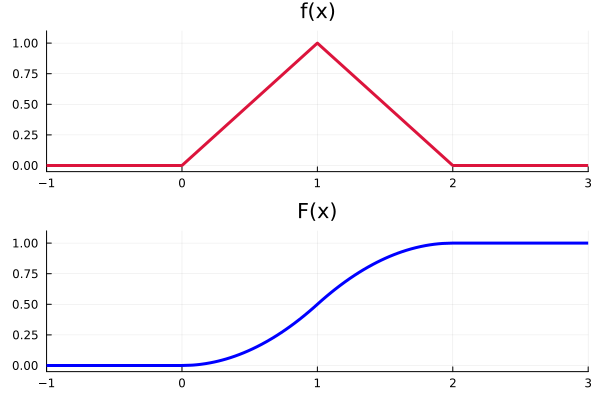

In [148]:
p1 = plot(d8, xlims=[-1,3], ylims=[-0.05,1.1],legend=false, lw=3, color=:crimson)
p2 = plot(F8, xlims=[-1,3], ylims=[-0.05,1.1],leg=false,lw=3, color=:blue)
plot(p1,p2, layout=(2,1), legend=false, title=["f(x)" "F(x)" ])

## Integración de funciones con Julia

El siguiente código muestra como calcular media, varianza y desviación estándar de una VA continua, usando el paquete `Quadgk` .

In [160]:
using QuadGK
quadgk(d8,0,1,2)
h1(x)=x*d8(x)
h2(x)=x^2*d8(x)
media = quadgk(h1,0,1,2)[1]
varianza = quadgk(h2,0,1,2)[1]-media^2
desv=√varianza
media, varianza, desv

(1.0, 0.16666666666666652, 0.40824829046386285)

## Tabla de la distribución normal estándar

In [150]:
using TypedTables, PrettyTables, Crayons, DataFrames
prob = cdf.(d3,0.0:0.01:3.49)
tabla = round.(transpose(reshape(prob,(10,35))),digits=4)
tabla = hcat(0.0:0.1:3.4,tabla)
y1=[j for j ∈ 0.00:0.01:0.09]
y1=string.(y1)
y1=pushfirst!(y1,"z ")
header= y1
hl_v = Highlighter((tabla, i, j) -> (j==1) ,crayon"blue bold")
pretty_table(tabla, header=header, header_crayon=crayon"blue bold", highlighters=(hl_v))

┌─────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┐
│  z  │    0.0 │   0.01 │   0.02 │   0.03 │   0.04 │   0.05 │   0.06 │   0.07 │   0.08 │   0.09 │
├─────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.0 │    0.5 │  0.504 │  0.508 │  0.512 │  0.516 │ 0.5199 │ 0.5239 │ 0.5279 │ 0.5319 │ 0.5359 │
│ 0.1 │ 0.5398 │ 0.5438 │ 0.5478 │ 0.5517 │ 0.5557 │ 0.5596 │ 0.5636 │ 0.5675 │ 0.5714 │ 0.5753 │
│ 0.2 │ 0.5793 │ 0.5832 │ 0.5871 │  0.591 │ 0.5948 │ 0.5987 │ 0.6026 │ 0.6064 │ 0.6103 │ 0.6141 │
│ 0.3 │ 0.6179 │ 0.6217 │ 0.6255 │ 0.6293 │ 0.6331 │ 0.6368 │ 0.6406 │ 0.6443 │  0.648 │ 0.6517 │
│ 0.4 │ 0.6554 │ 0.6591 │ 0.6628 │ 0.6664 │   0.67 │ 0.6736 │ 0.6772 │ 0.6808 │ 0.6844 │ 0.6879 │
│ 0.5 │ 0.6915 │  0.695 │ 0.6985 │ 0.7019 │ 0.7054 │ 0.7088 │ 0.7123 │ 0.7157 │  0.719 │ 0.7224 │
│ 0.6 │ 0.7257 │ 0.7291 │ 0.7324 │ 0.7357 │ 0.7389 │ 0.7422 │ 0.7454 │ 0.7486 │ 0.7517 │ 0.7549 │
│ 0.7 │  0.758 │ 0.7

In [151]:
prob = cdf.(d3,-3.49:0.01:0.0)
tabla = round.(transpose(reshape(prob,(10,35))),digits=4)
tabla = hcat(-3.4:0.1:0.0,tabla)
y1=[j for j ∈ 0.09:-0.01:0.00]
y1=string.(y1)
y1=pushfirst!(y1,"z ")
header= y1
hl_v = Highlighter((tabla, i, j) -> (j==1) ,crayon"blue bold")
pretty_table(tabla, header=header, header_crayon=crayon"blue bold", highlighters=(hl_v))

┌──────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┐
│   z  │   0.09 │   0.08 │   0.07 │   0.06 │   0.05 │   0.04 │   0.03 │   0.02 │   0.01 │    0.0 │
├──────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ -3.4 │ 0.0002 │ 0.0003 │ 0.0003 │ 0.0003 │ 0.0003 │ 0.0003 │ 0.0003 │ 0.0003 │ 0.0003 │ 0.0003 │
│ -3.3 │ 0.0003 │ 0.0004 │ 0.0004 │ 0.0004 │ 0.0004 │ 0.0004 │ 0.0004 │ 0.0005 │ 0.0005 │ 0.0005 │
│ -3.2 │ 0.0005 │ 0.0005 │ 0.0005 │ 0.0006 │ 0.0006 │ 0.0006 │ 0.0006 │ 0.0006 │ 0.0007 │ 0.0007 │
│ -3.1 │ 0.0007 │ 0.0007 │ 0.0008 │ 0.0008 │ 0.0008 │ 0.0008 │ 0.0009 │ 0.0009 │ 0.0009 │  0.001 │
│ -3.0 │  0.001 │  0.001 │ 0.0011 │ 0.0011 │ 0.0011 │ 0.0012 │ 0.0012 │ 0.0013 │ 0.0013 │ 0.0013 │
│ -2.9 │ 0.0014 │ 0.0014 │ 0.0015 │ 0.0015 │ 0.0016 │ 0.0016 │ 0.0017 │ 0.0018 │ 0.0018 │ 0.0019 │
│ -2.8 │ 0.0019 │  0.002 │ 0.0021 │ 0.0021 │ 0.0022 │ 0.0023 │ 0.0023 │ 0.0024 │ 0.0025 │ 0.0026 │
│ -2.7 │ 0

In [152]:
colores=Colors.color_names

Dict{String, Tuple{Int64, Int64, Int64}} with 666 entries:
  "darkorchid"     => (153, 50, 204)
  "chocolate"      => (210, 105, 30)
  "chocolate2"     => (238, 118, 33)
  "grey69"         => (176, 176, 176)
  "grey97"         => (247, 247, 247)
  "olivedrab3"     => (154, 205, 50)
  "deeppink2"      => (238, 18, 137)
  "mediumpurple2"  => (159, 121, 238)
  "ivory1"         => (255, 255, 240)
  "gray95"         => (242, 242, 242)
  "darkgoldenrod4" => (139, 101, 8)
  "lemonchiffon2"  => (238, 233, 191)
  "palegreen4"     => (84, 139, 84)
  "cornsilk4"      => (139, 136, 120)
  "red1"           => (255, 0, 0)
  "wheat1"         => (255, 231, 186)
  "lightpink4"     => (139, 95, 101)
  "wheat2"         => (238, 216, 174)
  "purple2"        => (145, 44, 238)
  ⋮                => ⋮

In [153]:
llaves = sort(collect(keys(colores)));

In [154]:
llaves[findall(x -> startswith.(x,"green"),llaves)]

6-element Vector{String}:
 "green"
 "green1"
 "green2"
 "green3"
 "green4"
 "greenyellow"

Los colores que empiezan con "gr".

In [155]:
colores["wheat"]

(245, 222, 179)

![Distribuciones continuas](Cont.jpg)

## Fórmulas Variable Aleatoria Continua

Toda fpd debe cumplir:


1. $f(x) \ge 0 \quad \forall x \in \mathbb{R}$
2. $\int_{-\infty}^{\infty}f(x) \, dx=1$


La función de distribución acumulada $F(x)$ (Fda), está dada por:

$$F(x)=P(X \le x)= \int_{-\infty}^{x}f(t) \, dt $$

### Propiedades


1. $\displaystyle\lim_{x \to -\infty} F(X)=0 $
2. $\displaystyle\lim_{x \to \infty} F(x)=1$
3. $F(x)$ es creciente.
4. $\displaystyle\frac{dF(x)}{dx}=f(x)$


### Media y varianza


1. $\displaystyle{\mu}_{X}=\mathbb{E}(X)=\int_{-\infty}^{\infty} xf(x)\,dx$
2. $\displaystyle{\sigma}^{2}=\mathbb{V}(X)=\int_{-\infty}^{\infty}x^{2}f(x)\, dx\quad - \quad {\mu}_{X}^{2}$
3. $\displaystyle{\mu}_{g(X)}=\mathbb{E}[g(X)]=\int_{-\infty}^{\infty}g(x)f(x)\,dx$
4. $\displaystyle{\sigma^{2}}_{g(x)}=\mathbb{V}[f(X)]=\mathbb{E}[g(X)^2]-\mathbb{E}[g(X)]^{2}=\int_{-\infty}^{\infty}g(x)^2f(x)\,dx-\left[\int_{-\infty}^{\infty}g(x)f(x)\,dx\right]^2$




### Propiedades

Sean $a$ y $b$ constantes y $X$ y $Y$ variables aleatorias (discretas o continuas), se cumple:

1. $\mathbb{E}(a)=a$
2. $\mathbb{E}(aX+b)=a\mathbb{E}(X)+b$
3. $\mathbb{V}(a)=0$
4. $\mathbb{V}(aX+b)=a^{2}\mathbb{V}(X)$



## Ejercicios propuestos

1.  Para f(x) fdp

$ f(x)=
\begin{cases}
c(1-x^2) & \text{si} \quad -1 \leq x < 1 \\
0 & \text{otro caso}
\end{cases}
$

    a. ¿Cuál es el valor de c?
    b. Halle la Fda
    c. Calcule media, varianza y desviación estándar

2. Halle C para que f sea fdp

$ f(x)=
\begin{cases}
Cxe^{-\frac{x}{2}} & \text{si} \quad x > 0 \\
0 & \text{si}\quad  x \le 0
\end{cases}
$

3. Halle $k$ para que $f(x)$ sea una fdp.

$ f(x)=
\begin{cases}
kx(1-x) & \text{si} \quad 0 \leq x < 1 \\
0 & \text{otro caso}
\end{cases}
$

4. Sea X va con F(x) Fda dada por:

$ F(x)=
\begin{cases}
0 & x < 0 \\
2x-x^2 &  0 \leq x < 1 \\
1 & x \ge 1
\end{cases}
$

    a. Hallar la fdp
    b. Calcular P(X < 0.2)
    c. P(0.1 < X < 0.6)
    d. Calcule media, varianza y desviación estándar

5. La fdp X del tiempo de vida de un componente electrónico, en horas, está dada por:

$ f(x)=
\begin{cases}
\frac{10}{x^2} &   x > 10 \\
0 & x \le 10
\end{cases}
$

    a. Hallar la Fda
    b. Encontrar P(X > 20)
    c. ¿Cuál es la probabilidad de que de 6 de estos componentes al menos 3 funcionen por lo menos 15 horas?

6. Una estación de gasolina es surtida semanalmente. El volumen de ventas semanales X, en miles de galones, es una variable aleatoria con fdp dada por:

$ f(x)=
\begin{cases}
5(1-x)^4 & 0 <  x < 1 \\
0 & \text{otro caso}
\end{cases}
$

    a. Hallar la Fda
    b. ¿Cuál es la probabilidad de que en una semana dada venda más de 800 galones?
    c. Si el tanque tiene una capacidad de 700 galones, ¿Cuál es la probabilidad de que se quede sin gasolina?
    d. ¿Cuál debe ser la capacidad del tanque para que la probabilidad de que se quede sin gasolina sea de 0.01?




## Ejercicio 6.d

$\int_{k}^{1}5(1-x)^4\,dx=0.01$

In [161]:
using Roots
f1(x)=5*(1-x)^4

f1 (generic function with 1 method)

In [162]:
f2(x)=quadgk(f1,x,1)[1]-.01

f2 (generic function with 1 method)

In [163]:
find_zero(f2,0.5)

0.6018928294465028

## Distribución t de Student

In [44]:
using Distributions, DataFrames, PrettyTables, TypedTables, Crayons
alphas = [0.005, 0.01, 0.05, 0.1]
area=1:4
ν = collect(1:30)
prob = zeros(Float64, 30, 4)
for i in ν
    for j in area
        dt = TDist(i)
        prob[i,j] = cquantile(dt, alphas[j])
    end
end
tabla = round.(prob, digits=4)
tabla = hcat(ν, tabla)
alphas=string.(alphas)
alphas =pushfirst!(alphas,"gl ")
header= alphas

hl_v = Highlighter((tabla, i, j) -> (j==1) ,crayon"blue bold")
pretty_table(tabla, header=header, header_crayon=crayon"blue bold", highlighters=(hl_v))


┌──────┬─────────┬─────────┬────────┬────────┐
│  gl  │   0.005 │    0.01 │   0.05 │    0.1 │
├──────┼─────────┼─────────┼────────┼────────┤
│  1.0 │ 63.6567 │ 31.8205 │ 6.3138 │ 3.0777 │
│  2.0 │  9.9248 │  6.9646 │   2.92 │ 1.8856 │
│  3.0 │  5.8409 │  4.5407 │ 2.3534 │ 1.6377 │
│  4.0 │  4.6041 │  3.7469 │ 2.1318 │ 1.5332 │
│  5.0 │  4.0321 │  3.3649 │  2.015 │ 1.4759 │
│  6.0 │  3.7074 │  3.1427 │ 1.9432 │ 1.4398 │
│  7.0 │  3.4995 │   2.998 │ 1.8946 │ 1.4149 │
│  8.0 │  3.3554 │  2.8965 │ 1.8595 │ 1.3968 │
│  9.0 │  3.2498 │  2.8214 │ 1.8331 │  1.383 │
│ 10.0 │  3.1693 │  2.7638 │ 1.8125 │ 1.3722 │
│ 11.0 │  3.1058 │  2.7181 │ 1.7959 │ 1.3634 │
│ 12.0 │  3.0545 │   2.681 │ 1.7823 │ 1.3562 │
│ 13.0 │  3.0123 │  2.6503 │ 1.7709 │ 1.3502 │
│ 14.0 │  2.9768 │  2.6245 │ 1.7613 │  1.345 │
│ 15.0 │  2.9467 │  2.6025 │ 1.7531 │ 1.3406 │
│ 16.0 │  2.9208 │  2.5835 │ 1.7459 │ 1.3368 │
│ 17.0 │  2.8982 │  2.5669 │ 1.7396 │ 1.3334 │
│ 18.0 │  2.8784 │  2.5524 │ 1.7341 │ 1.3304 │
│ 19.0 │  2.8

## Otra tabla de Normal

In [68]:
x=collect(0.00:0.05:3.10)
x[27]=1.282
x[35]=1.645
x[51]=2.326
x[57]=2.576
Φx = round.(cdf.(Normal(),x), digits=4)
Tab = [x Φx]
Tab1 = Tab[1:21, :]
Tab2 = Tab[22:42, :]
Tab3 = Tab[43:63, :]
Tab = hcat(Tab1, Tab2, Tab3)
header = ["x", "Φ(x)","x", "Φ(x)","x", "Φ(x)"] 
hl_v1 = Highlighter((tabla, i, j) -> (j==1) ,crayon"blue bold")
hl_v2 = Highlighter((tabla, i, j) -> (j==3) ,crayon"blue bold")
hl_v3 = Highlighter((tabla, i, j) -> (j==5) ,crayon"blue bold")
pretty_table(Tab, header=header, header_crayon=crayon"blue bold", highlighters=(hl_v1,hl_v2,hl_v3))

┌──────┬────────┬───────┬────────┬───────┬────────┐
│    x │   Φ(x) │     x │   Φ(x) │     x │   Φ(x) │
├──────┼────────┼───────┼────────┼───────┼────────┤
│  0.0 │    0.5 │  1.05 │ 0.8531 │   2.1 │ 0.9821 │
│ 0.05 │ 0.5199 │   1.1 │ 0.8643 │  2.15 │ 0.9842 │
│  0.1 │ 0.5398 │  1.15 │ 0.8749 │   2.2 │ 0.9861 │
│ 0.15 │ 0.5596 │   1.2 │ 0.8849 │  2.25 │ 0.9878 │
│  0.2 │ 0.5793 │  1.25 │ 0.8944 │   2.3 │ 0.9893 │
│ 0.25 │ 0.5987 │ 1.282 │ 0.9001 │  2.35 │ 0.9906 │
│  0.3 │ 0.6179 │  1.35 │ 0.9115 │   2.4 │ 0.9918 │
│ 0.35 │ 0.6368 │   1.4 │ 0.9192 │  2.45 │ 0.9929 │
│  0.4 │ 0.6554 │  1.45 │ 0.9265 │ 2.326 │   0.99 │
│ 0.45 │ 0.6736 │   1.5 │ 0.9332 │  2.55 │ 0.9946 │
│  0.5 │ 0.6915 │  1.55 │ 0.9394 │   2.6 │ 0.9953 │
│ 0.55 │ 0.7088 │   1.6 │ 0.9452 │  2.65 │  0.996 │
│  0.6 │ 0.7257 │  1.65 │ 0.9505 │   2.7 │ 0.9965 │
│ 0.65 │ 0.7422 │ 1.645 │   0.95 │  2.75 │  0.997 │
│  0.7 │  0.758 │  1.75 │ 0.9599 │ 2.576 │  0.995 │
│ 0.75 │ 0.7734 │   1.8 │ 0.9641 │  2.85 │ 0.9978 │
│  0.8 │ 0.7